# PBMC3k: Final Results for PCA, CAVI, and Gibbs

This notebook summarizes the final results of the fixed workflow: `X_scaled`, `K=50`, `b_sigma=1`, RSP, loading-column L2-norm weighting, and the first 20 columns (`d20_norm`). CAVI uses float64 and Gibbs uses float32. Their Leiden resolutions are **0.425** and **0.500**, respectively, and both methods produce **9 clusters**.

Cluster labels in the figures start at 1, while the underlying result files retain the original zero-based labels. ARI/AMI measure clustering agreement, not cell-type accuracy. This notebook reads saved results only and does not refit the models.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import scanpy as sc
from IPython.display import Image, display
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 180)

ROOT = Path.cwd()
if not (ROOT / 'PBMC').is_dir():
    ROOT = ROOT.parent
DATA = ROOT / 'PBMC' / 'data'
FIGURES = ROOT / 'PBMC' / 'figures' / 'mgp_seurat'

RUNS = {
    'PCA': 'pca_mgp_seurat_aligned',
    'CAVI': 'cavi_seurat_k50_d20',
    'GS': 'gibbs_seurat_k50_n20000_b10000_t10_d20',
}
REPRESENTATIONS = {'PCA': 'd50', 'CAVI': 'd20_norm', 'GS': 'd20_norm'}
ORDER = ['PCA', 'CAVI', 'GS']

adatas = {
    name: sc.read_h5ad(DATA / f'{run_id}.h5ad')
    for name, run_id in RUNS.items()
}
payloads = {}
for name in ('CAVI', 'GS'):
    with np.load(DATA / f'{RUNS[name]}_model.npz', allow_pickle=False) as z:
        payloads[name] = json.loads(z['diagnostics_json'].item())
comparison = json.loads((DATA / 'seurat_comparison.json').read_text(encoding='utf-8'))
validation = json.loads((DATA / 'seurat_validation.json').read_text(encoding='utf-8'))

def labels(name):
    key = f"leiden_{RUNS[name]}_{REPRESENTATIONS[name]}"
    raw = adatas[name].obs[key].astype(int)
    return pd.Series((raw + 1).astype(str), index=raw.index, dtype='category')

print({name: adatas[name].shape for name in ORDER})
print({'validation': validation['status'], 'input_sha256': validation['input_sha256']})

{'PCA': (2638, 13714), 'CAVI': (2638, 13714), 'GS': (2638, 13714)}
{'validation': 'passed', 'input_sha256': '689dc2d0912196ff1b0883d6caef514e56e39dc10f3cf3eaad3e23eb3653dbeb'}


## 1. Cluster counts and ARI/AMI

PCA is used only as a reference and not as ground truth for cell types. AMI stands for adjusted mutual information.

In [2]:
rows = []
for name in ORDER:
    rows.append({
        'Method': name,
        'Clusters': labels(name).nunique(),
        'ARI vs PCA50': adjusted_rand_score(labels('PCA'), labels(name)),
        'AMI vs PCA50': adjusted_mutual_info_score(labels('PCA'), labels(name)),
    })
metrics = pd.DataFrame(rows).set_index('Method')
display(metrics.round(4))
print(f"CAVI vs GS: ARI={comparison['cavi_vs_gibbs']['ari']:.4f}, AMI={comparison['cavi_vs_gibbs']['ami']:.4f}")

,Clusters,ARI vs PCA50,AMI vs PCA50
Method,,,
PCA,7,1.0000,1.0000
CAVI,9,0.6148,0.7732
GS,9,0.5270,0.7434


CAVI vs GS: ARI=0.7776, AMI=0.8460


In [3]:
cluster_sizes = pd.DataFrame({name: labels(name).value_counts().sort_index() for name in ORDER})
cluster_sizes = cluster_sizes.astype('Int64')
cluster_sizes.index.name = 'Cluster'
display(cluster_sizes)

,PCA,CAVI,GS
Cluster,,,
1,1172,301,298
2,346,179,445
3,177,622,395
4,441,496,316
5,462,53,343
6,27,343,480
7,13,485,142
8,<NA>,145,164
9,<NA>,14,55


## 2. UMAP clustering plots

UMAP is used for visualization only and is not, by itself, evidence of superior algorithm performance.

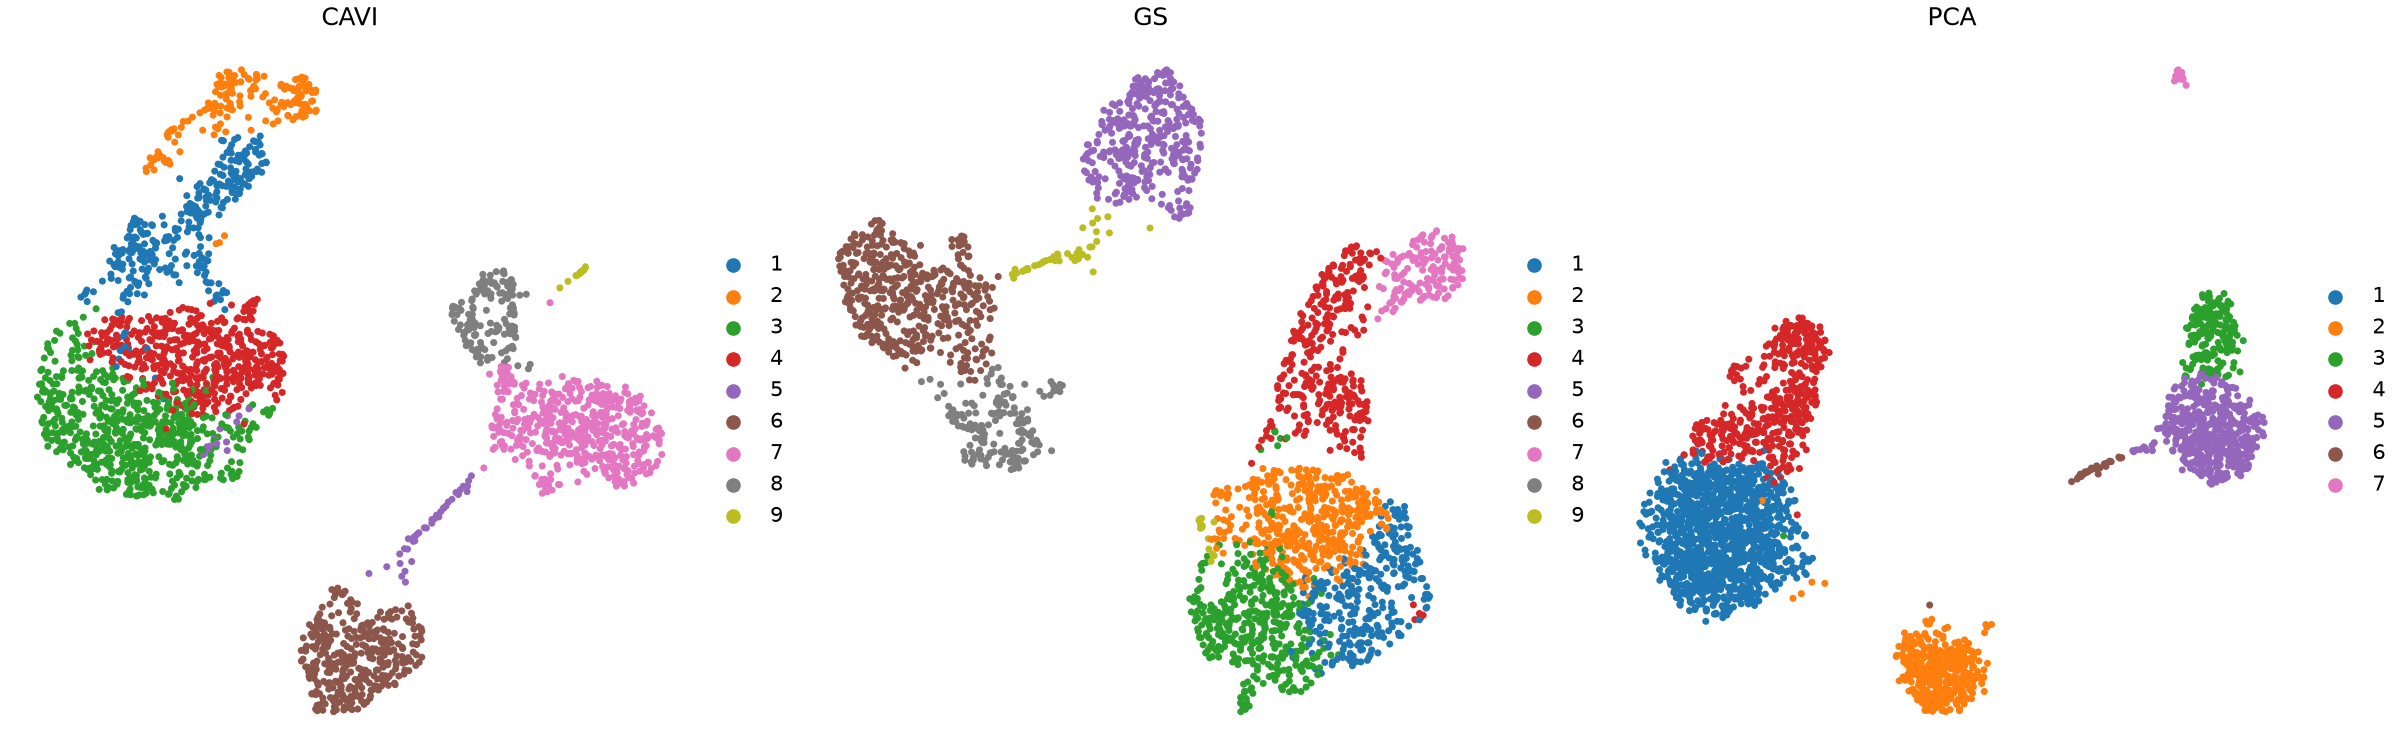

In [4]:
display(Image(filename=str(FIGURES / 'comparison_umap.png'), width=1200))

## 3. Top 5 markers per cluster

Marker analysis uses all quality-controlled genes in `lognorm`, the Wilcoxon test, and Benjamini-Hochberg correction. Full scores, log fold changes, and p-values are stored in the corresponding CSV files.

In [5]:
marker_files = {
    'PCA': DATA / 'pca_mgp_seurat_aligned_d50_top5_markers.csv',
    'CAVI': DATA / 'cavi_seurat_k50_d20_d20_norm_top5_markers.csv',
    'GS': DATA / 'gibbs_seurat_k50_n20000_b10000_t10_d20_d20_norm_top5_markers.csv',
}
marker_rows = []
for name in ORDER:
    frame = pd.read_csv(marker_files[name])
    for raw_cluster, group in frame.groupby('cluster', sort=True):
        marker_rows.append({
            'Method': name,
            'Cluster': int(raw_cluster) + 1,
            'Top 5 markers': ', '.join(group['gene'].head(5).astype(str)),
        })
marker_table = pd.DataFrame(marker_rows)
display(marker_table)

,Method,Cluster,Top 5 markers
0,PCA,1,"LDHB, RPS12, RPS25, RPS6, RPS27"
1,PCA,2,"CD74, HLA-DRA, CD79A, CD79B, HLA-DPB1"
2,PCA,3,"LST1, FCER1G, AIF1, COTL1, FTH1"
3,PCA,4,"NKG7, CST7, GZMA, B2M, CTSW"
4,PCA,5,"LYZ, S100A9, S100A8, TYROBP, FTL"
5,PCA,6,"HLA-DPA1, HLA-DPB1, HLA-DRB1, HLA-DRA, CST3"
6,PCA,7,"PF4, SDPR, GNG11, PPBP, NRGN"
7,CAVI,1,"CCL5, NKG7, B2M, GZMA, CST7"
8,CAVI,2,"NKG7, CTSW, CST7, GNLY, GZMA"
9,CAVI,3,"RPS12, RPS27, RPS6, RPL32, RPS14"


## 4. Model, tuning, and sampling diagnostics

The CAVI sweep count includes both the initial run and the warm-start continuation. ESS, MCSE, and split-chain diagnostics are retained for Gibbs; a single long chain does not prove that the full posterior has been adequately explored.

In [6]:
cavi_d = payloads['CAVI']['diagnostics']
gs_d = payloads['GS']['diagnostics']
cavi_fit = cavi_d['fit']
gs_fit = gs_d['fit']
gs_sampling = gs_d['sampling']
cavi_config = payloads['CAVI']['config']
gs_config = payloads['GS']['config']

rows = [
    ('Input', 'X_scaled', 'X_scaled'),
    ('K', 50, 50),
    ('Precision', 'float64', 'float32'),
    ('Prior', 'nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1', 'same'),
    ('RSP status', cavi_d['rsp']['status_code'], gs_d['rsp']['status_code']),
    ('Score weighting', 'loading_column_l2_norm', 'loading_column_l2_norm'),
    ('Report columns', 20, 20),
    ('Leiden resolution', cavi_config['leiden_resolution'], gs_config['leiden_resolution']),
    ('Report clusters', labels('CAVI').nunique(), labels('GS').nunique()),
    ('Fit sweeps', cavi_fit.get('total_sweeps', cavi_fit['n_iter']), gs_fit['n_iter']),
    ('Burn-in', '—', gs_fit['burn_in']),
    ('Thin', '—', gs_fit['thin']),
    ('Kept draws', '—', gs_fit['n_kept']),
    ('Converged / Gamma', f"{cavi_fit['converged']} / {cavi_fit['stop_reason']}", gs_fit['gamma_mode']),
    ('Active factors (full)', cavi_d['representation']['active_factor_count'], gs_d['representation']['active_factor_count']),
    ('Active factors (first 20)', cavi_d['representation']['representations']['d20_norm']['selected_active_factor_count'], gs_d['representation']['representations']['d20_norm']['selected_active_factor_count']),
    ('Active-loading ESS>=400 coverage', '—', gs_sampling['active_loading_bulk_ess']['coverage_at_400']),
    ('Median bulk ESS (active loadings)', '—', gs_sampling['active_loading_bulk_ess']['median']),
    ('Minimum bulk ESS (loadings)', '—', gs_sampling['bulk_summary']['B']['min']),
    ('Minimum bulk ESS (noise variances)', '—', gs_sampling['bulk_summary']['sigma2']['min']),
    ('Review required', '—', gs_sampling['review_required']),
    ('Validation', validation['status'], validation['status']),
]
diagnostics = pd.DataFrame(rows, columns=['Item', 'CAVI', 'GS'])
display(diagnostics)

,Item,CAVI,GS
0,Input,X_scaled,X_scaled
1,K,50,50
2,Precision,float64,float32
3,Prior,"nu=3, a1=2.1, a2=3.1, a_sigma=1, b_sigma=1",same
4,RSP status,1,1
5,Score weighting,loading_column_l2_norm,loading_column_l2_norm
6,Report columns,20,20
7,Leiden resolution,0.425,0.5
8,Report clusters,9,9
9,Fit sweeps,1256,20000


## 5. Loading-column L2 norms before and after RSP

CAVI compares `mu_` with `mu_aligned_`; Gibbs compares the posterior mean loadings before and after RSP alignment.

CAVI


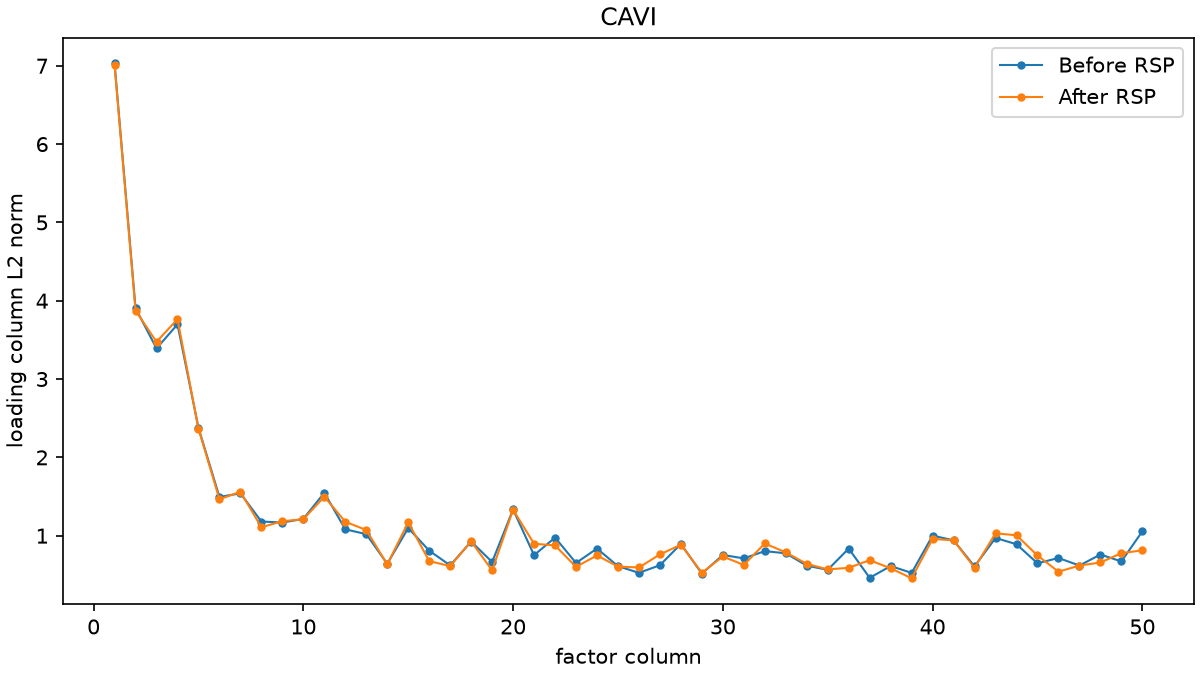

GS


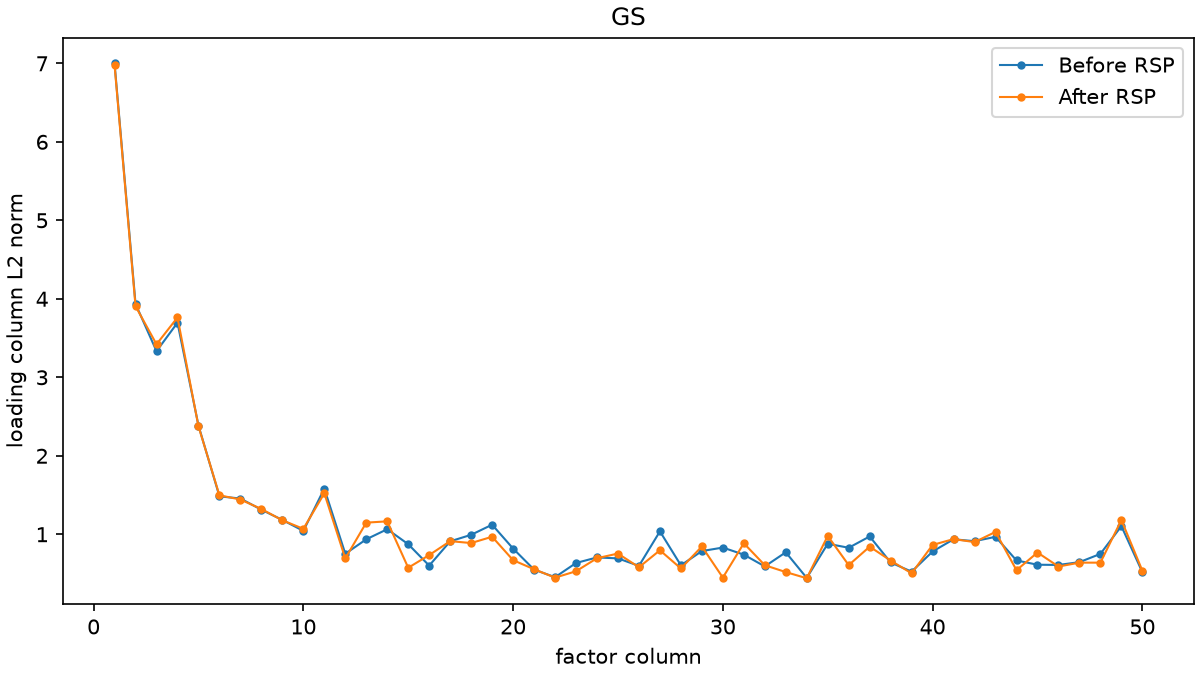

In [7]:
print('CAVI')
display(Image(filename=str(FIGURES / 'loading_column_norms_cavi.png'), width=1000))
print('GS')
display(Image(filename=str(FIGURES / 'loading_column_norms_gibbs.png'), width=1000))

## 6. Stability across Leiden seeds and neighbor counts

In [8]:
stability_frames = []
for name in ORDER:
    frame = pd.read_csv(DATA / f'{RUNS[name]}_stability_summary.csv')
    frame.insert(0, 'Method', name)
    stability_frames.append(frame)
stability = pd.concat(stability_frames, ignore_index=True)
stability = stability[[
    'Method', 'representation', 'seed_pairwise_ari_min',
    'seed_pairwise_ari_median', 'neighbor_ari_min', 'neighbor_cluster_counts'
]]
display(stability.round(4))

,Method,representation,seed_pairwise_ari_min,seed_pairwise_ari_median,neighbor_ari_min,neighbor_cluster_counts
0,PCA,d50,0.9561,0.9850,0.9699,"[7, 7, 7]"
1,CAVI,d20_norm,0.7144,0.8046,0.6862,"[9, 8, 6]"
2,GS,d20_norm,0.7041,0.7669,0.7182,"[9, 8, 8]"


## 7. Additional diagnostic plots

cluster_sizes.png


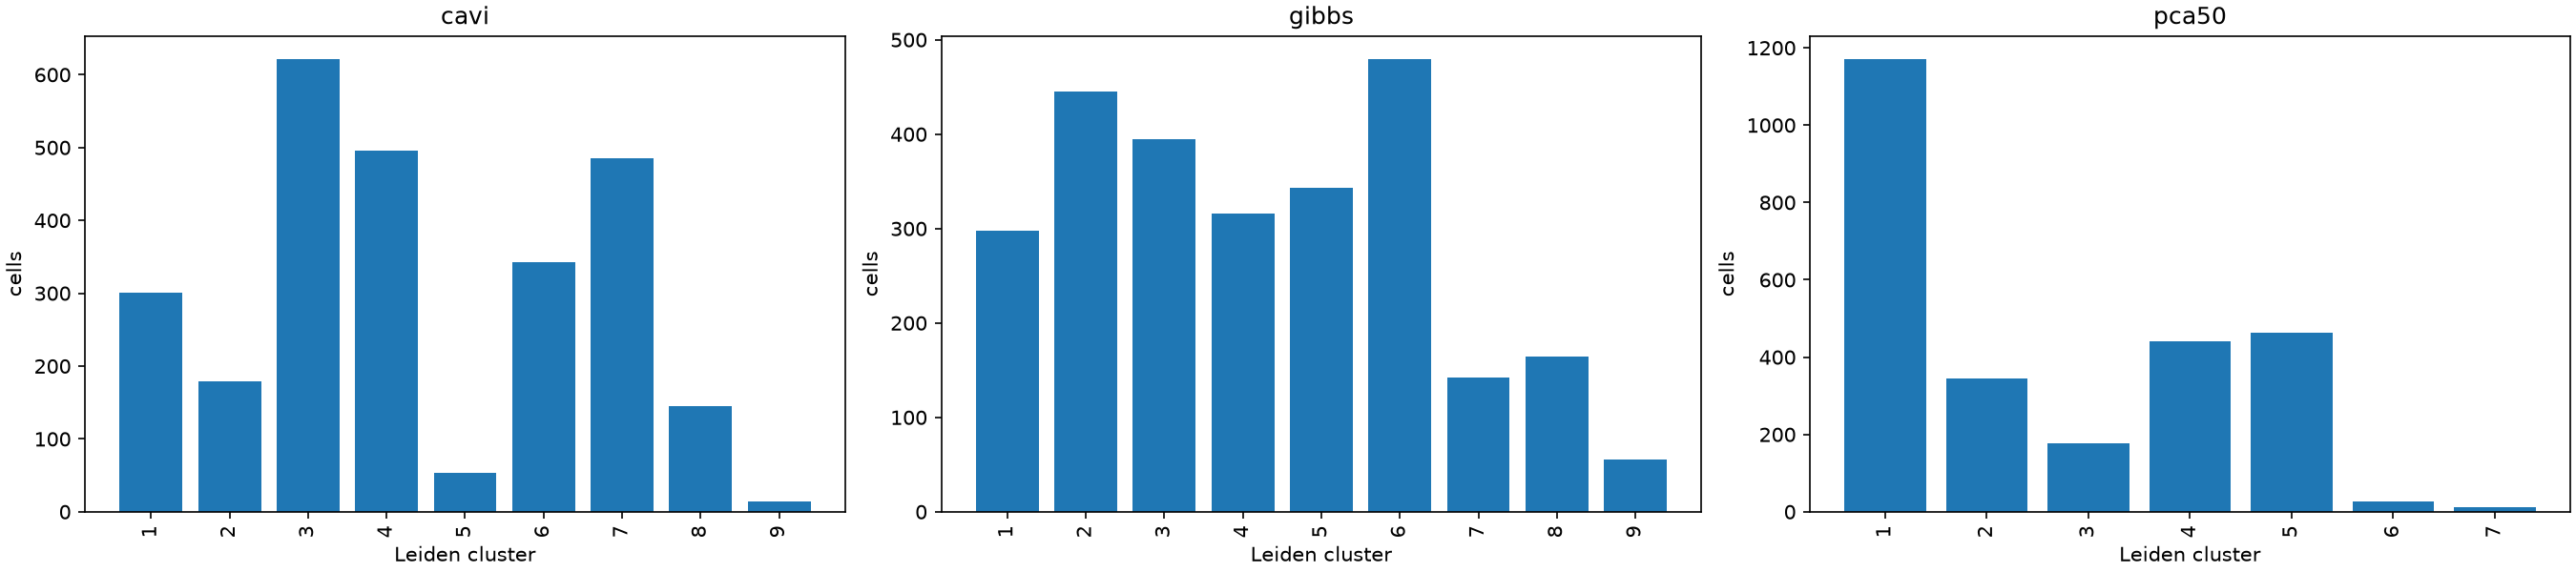

score_spectra.png


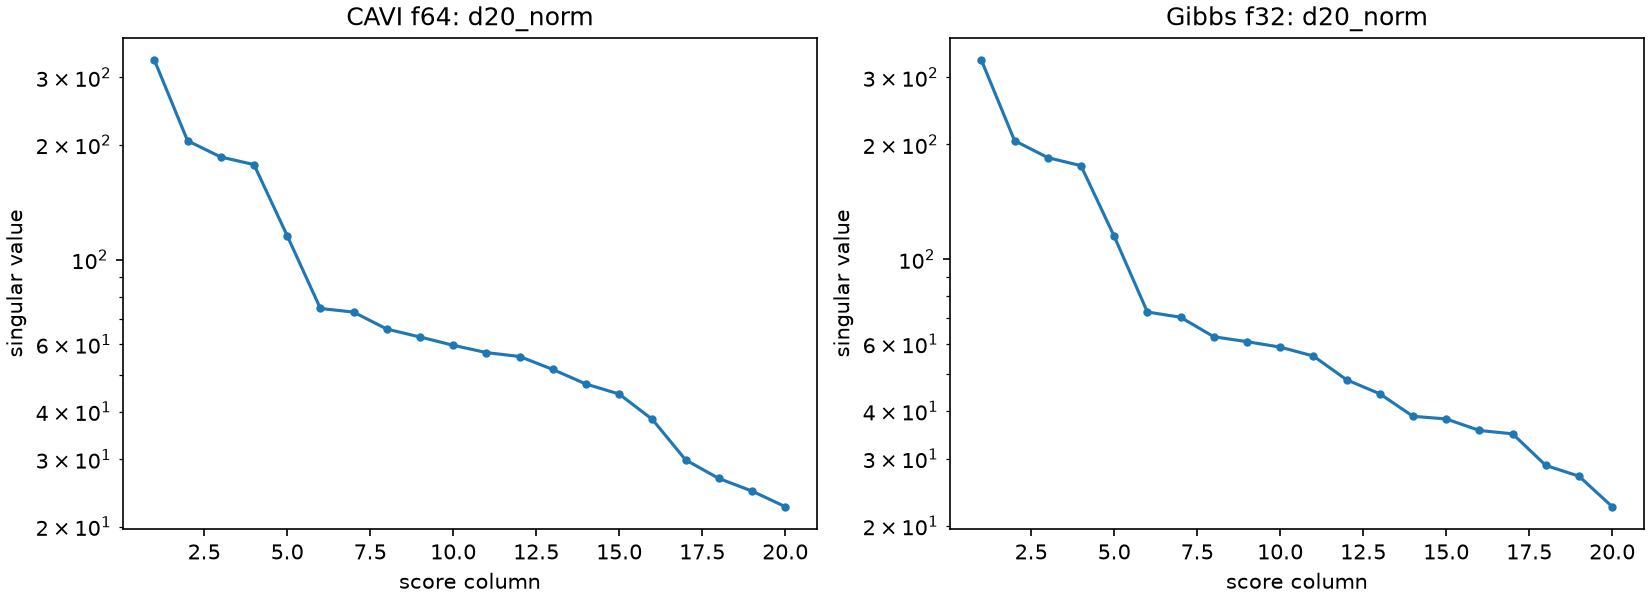

cavi_elbo.png


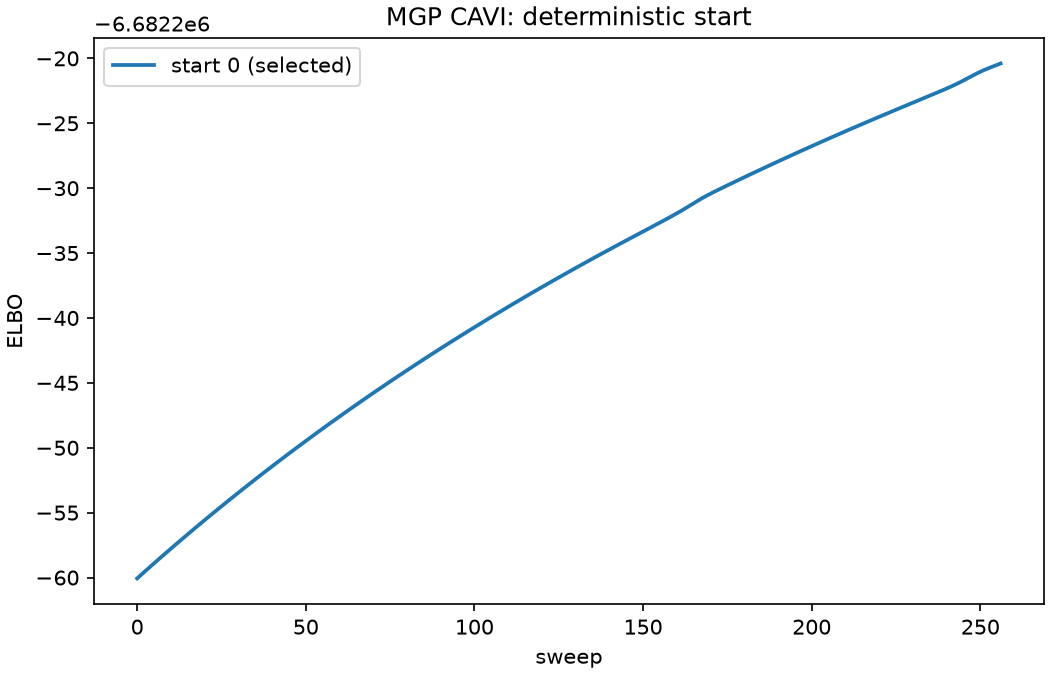

gibbs_ess.png


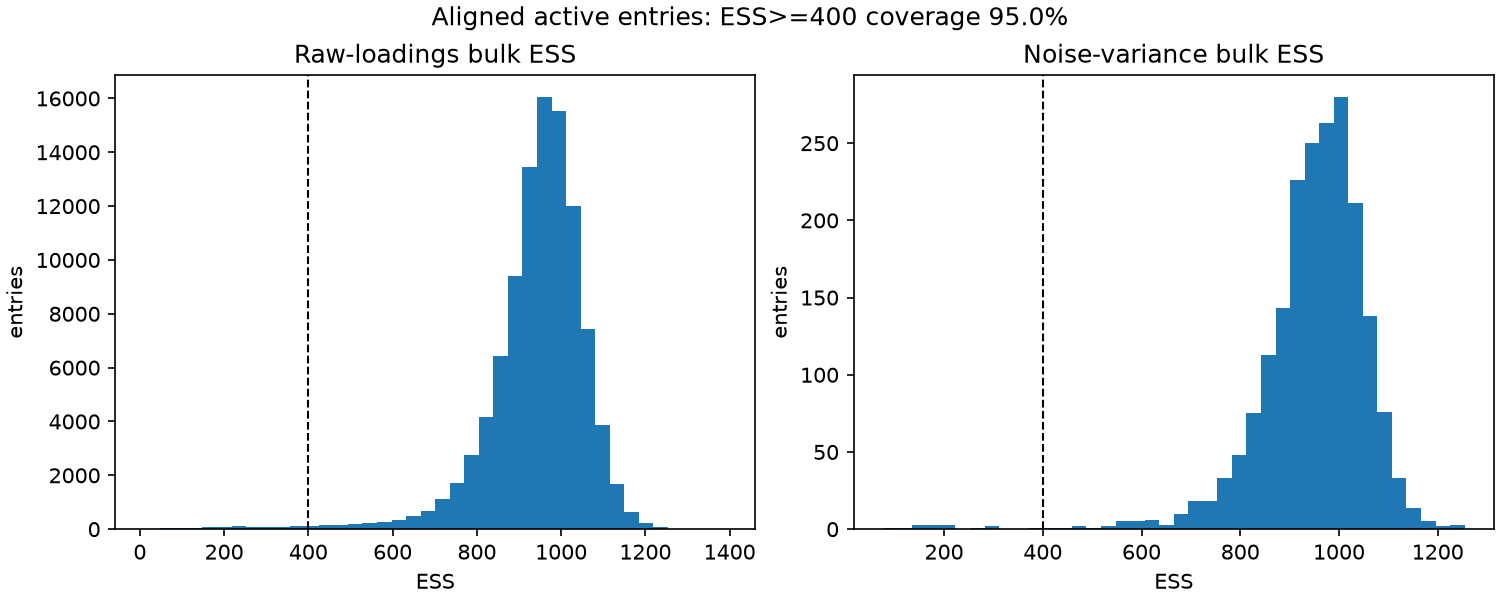

In [9]:
for filename in ('cluster_sizes.png', 'score_spectra.png', 'cavi_elbo.png', 'gibbs_ess.png'):
    print(filename)
    display(Image(filename=str(FIGURES / filename), width=1000))

## 8. Final validation

- CAVI satisfies `tol`, and both RSP runs have `status_code=1`.
- Both score matrices are weighted by loading-column norms before selecting the first 20 columns.
- CAVI and Gibbs both produce 9 clusters, with exactly 5 markers per cluster.
- Cluster labels in the figures start at 1.
- `seurat_analysis.py --stage validate` returns `passed`, and all report links are valid.

See `PBMC/reproduce.md` for reproduction commands and the fixed configuration, and `PBMC/plan.md` for the sole workflow.

In [10]:
summary = pd.DataFrame([
    ('Status', validation['status']),
    ('CAVI precision', validation['cavi_precision']),
    ('Gibbs precision', validation['gibbs_precision']),
    ('Gibbs chain shape', tuple(validation['gibbs_chain_shape'])),
    ('Score shape', tuple(validation['score_shape'])),
    ('PCA dimensions', tuple(validation['pca_dimensions'])),
    ('Report links', validation['report_links']),
], columns=['Item', 'Value'])
display(summary)

,Item,Value
0,Status,passed
1,CAVI precision,float64
2,Gibbs precision,float32
3,Gibbs chain shape,"(1000, 2000, 50)"
4,Score shape,"(2638, 20)"
5,PCA dimensions,"(2638, 50)"
6,Report links,14
